
# BAN 5100 - Final Exam: JLL / GSA Lease Portfolio

**Student:** Alisha Pokharel

**Course:** BAN 5100 - Data Visualization & Inferential Statistics

**Professor:** Omar El Mghari

**Semester:** Fall 2026

**Part 1:** Data Cleanup

**Dataset:** `cs1_gsa_leases_2026_08.csv`

---

## Project Overview

This notebook uses the earlier example Discovery cleaning methods covered in class to clean and prepare the GSA lease dataset for analysis.

## Objectives - Web Exercise 4

1. Where does the federal government pay the most rent?
2. Where are large portions of that rent coming up for renewal in the next two years?
3. Can you map this information by state and explain what it means for our leasing strategy?


# 0. Setup

## Step 1 - Check R Runtime

This project uses R in Google Colab. The following code checks the R version before loading the packages and GSA lease dataset.

In [10]:
R.version.string

[1] "R version 4.6.1 (2026-06-24)"


## Step 2 - Load the tidyverse

The tidyverse package includes tools for importing, cleaning, analyzing, and visualizing data. I will use these tools to prepare the GSA lease dataset for analysis.


In [11]:
# Install only if not already present
if (!requireNamespace("tidyverse", quietly = TRUE)) {
  install.packages("tidyverse")
}

In [12]:
library(tidyverse)


## Step 3 - Upload the GSA Lease Dataset

Upload the original CS1 GSA lease dataset to Google Colab.

The dataset contains information about federal government leases, including annual rent, lease expiration dates, and geographic locations.


In [13]:
list.files("/content")

[1] "cs1_gsa_leases_2026_08.csv" "sample_data"

I confirm the uploaded GSA CSV is available before reading it. The next cell checks the exact Colab path used for this project.

In [14]:
# I point to the original GSA lease file uploaded to Colab.
data_path <- "/content/cs1_gsa_leases_2026_08.csv"
file.exists(data_path)


[1] TRUE


# 1. First Contact

Load the original GSA lease dataset and take a first look at its structure.

Before cleaning the data, I will check the number of rows and columns, look at a few records, and examine the column names and data types.


In [15]:

# Changed 'raw' to 'leases' to match the GSA lease dataset.
leases <- read_csv(data_path, show_col_types = FALSE)


`nrow()` counts rows. Each row is one record — though *what kind* of record is a question we settle in Section 5.

In [16]:
nrow(leases)

[1] 7368

`ncol()` counts columns.

In [17]:
ncol(leases)

[1] 42

`head()` shows the first few rows so you can see actual values.

In [18]:
head(leases, 3)

region,region_name,lease_num,location_code,city,county,address,state,zip,latitude,⋯,total_parking,lease_term_yrs,remaining_term_yrs,firm_term_remaining_yrs,lease_age_yrs,expiration_year,holdover_flag,in_soft_term,rsf_band,data_quality_flag
<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
1,New England,LCT00579,CT0047,WATERBURY,NAUGATUCK VALLEY PLANNING REGI,135 GRAND ST,CT,06702-9998,41.55365,⋯,0,5,1.08,1.08,3.92,2027,N,N,<2.5k,ok
1,New England,LCT04970,CT3316,EAST HARTFORD,CAPITOL PLANNING REGION,130 DARLIN ST,CT,06108-3234,41.76495,⋯,164,10,1.33,0.00,8.66,2027,N,Y,25k-100k,ok
1,New England,LCT04610,CT3319,STAMFORD,WESTERN CONNECTICUT PLANNING R,101 BROAD ST,CT,06901-2797,41.05516,⋯,8,15,1.75,0.00,13.25,2028,N,Y,2.5k-10k,ok


`glimpse()` is the most useful first look in R. One line per column showing its name, its type, and sample values.

Types you will see: `<chr>` text, `<dbl>` number, `<date>` date.

In [19]:
glimpse(leases, width = 100)

Rows: 7,368
Columns: 42
$ region                     <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, …
$ region_name                <chr> "New England", "New England", "New England", "New England", "Ne…
$ lease_num                  <chr> "LCT00579", "LCT04970", "LCT04610", "LCT04939", "LCT00331", "LC…
$ location_code              <chr> "CT0047", "CT3316", "CT3319", "CT3323", "CT3331", "CT3331", "CT…
$ city                       <chr> "WATERBURY", "EAST HARTFORD", "STAMFORD", "EAST HARTFORD", "NEW…
$ county                     <chr> "NAUGATUCK VALLEY PLANNING REGI", "CAPITOL PLANNING REGION", "W…
$ address                    <chr> "135 GRAND ST", "130 DARLIN ST", "101 BROAD ST", "333 E RIVER D…
$ state                      <chr> "CT", "CT", "CT", "CT", "CT", "CT", "CT", "CT", "CT", "CT", "CT…
$ zip                        <chr> "06702-9998", "06108-3234", "06901-2797", "06108-4200", "06510-…
$ latitude                   <dbl> 41.55365, 41.76495, 41.05516, 41.75880, 4


### Initial Observation

The original GSA lease dataset contains 7,368 rows and 42 columns. It includes information about annual rent, lease expiration dates, and lease locations.

Before using the data for analysis, I need to check the column names, missing values, duplicates, and data types.



### QUESTION 1 - Understanding the GSA Lease Data

Before cleaning the dataset, I looked at the column names and selected three lease-related fields to understand what they represent.

**1. `annual_rent`**

This column shows the annual rent associated with each lease. It will help identify where the federal government pays the most rent.

**2. `lease_expiration`**

This column shows the lease expiration date. It will help identify leases that are coming up for expiration within the next two years.

**3. `holdover_flag`**

This column indicates whether a lease is identified as a holdover. A holdover generally refers to occupancy continuing after the original lease term has expired. This field may help us better understand lease status and renewal exposure.


# 2. Checking Column Names

Before cleaning the data, I will check the column names to see if there are any formatting issues, such as extra spaces or line breaks.

In [20]:

# Check the column names in the original GSA lease dataset.
names(leases)


[1] "region"                     "region_name"               
 [3] "lease_num"                  "location_code"             
 [5] "city"                       "county"                    
 [7] "address"                    "state"                     
 [9] "zip"                        "latitude"                  
[11] "longitude"                  "field_office_name"         
[13] "central_business_unit"      "lease_effective"           
[15] "lease_expiration"           "termination_right_date"    
[17] "latest_action"              "fully_serviced"            
[19] "rsf"                        "lease_structured_parking"  
[21] "lease_surface_parking"      "percent_building"          
[23] "annual_rent"                "percent_office"            
[25] "percent_warehouse"          "percent_special"           
[27] "renewal_option_months_left" "renewal_options_left"      
[29] "lessor"                     "snapshot_date"             
[31] "space_type"                 "rent_per_rsf"              
[33] "total_parking"              "lease_term_yrs"            
[35] "remaining_term_yrs"         "firm_term_remaining_yrs"   
[37] "lease_age_yrs"              "expiration_year"           
[39] "holdover_flag"              "in_soft_term"              
[41] "rsf_band"                   "data_quality_flag"


I will check whether any column names contain line breaks.

The `grepl()` function searches for a pattern in the column names. Here, `[\r\n]` checks for line breaks.

In [21]:

# Check if any column names contain line breaks.
names(leases)[grepl("[\r\n]", names(leases))]


character(0)


No column names contain line breaks in the GSA lease dataset, so there is nothing to fix for this issue.

I will continue checking the column names for other formatting issues, such as extra spaces or special characters.


### Cleaning Column Names

I will start by making a copy of the original column names. This will allow me to check and clean the names before updating them in the dataset.

In [22]:

# Make a copy of the current column names.
new_names <- names(leases)

# View the first 12 column names before cleaning.
head(new_names, 12)

[1] "region"            "region_name"       "lease_num"        
 [4] "location_code"     "city"              "county"           
 [7] "address"           "state"             "zip"              
[10] "latitude"          "longitude"         "field_office_name"

### Remove Line Breaks from Column Names

I check for line breaks and remove any if present. The original GSA headers did not need changes in this step.


In [23]:

# Remove any line breaks from the column names.
new_names <- gsub("[\r\n]", "", new_names)


### Remove Extra Spaces from Column Names

I will use `trimws()` to remove any extra spaces at the beginning or end of the column names. This helps keep the names consistent and easier to use in the analysis.

In [24]:

# Remove extra spaces from the beginning and end of column names.
new_names <- trimws(new_names)


### Replace Special Characters in Column Names

I will check for special characters or spaces in the column names and replace them with underscores.

The `gsub()` function uses `[^A-Za-z0-9]+` to find one or more characters that are not letters or numbers and replace them with a single underscore.

This will help keep the column names consistent.


In [25]:

# Replace special characters or spaces with underscores.
new_names <- gsub("[^A-Za-z0-9]+", "_", new_names)



### Remove Extra Underscores from Column Names

I will remove any underscores at the beginning or end of the column names. This helps keep the names consistent after replacing special characters in the previous step.


In [26]:

# Remove underscores from the beginning or end of column names.
new_names <- gsub("^_|_$", "", new_names)



### Convert Column Names to Lowercase

I will use `tolower()` to make sure all column names are lowercase. This helps keep the names consistent and avoids issues when referring to columns later in the analysis.


In [27]:

# Convert all column names to lowercase.
new_names <- tolower(new_names)



### Check for Duplicate Column Names

After cleaning the column names, I will check whether any names are repeated.

The `duplicated()` function helps identify column names that appear more than once. This is important because duplicate names can cause problems when selecting or analyzing columns.


In [28]:

# Check if any column names are duplicated after cleaning.
new_names[duplicated(new_names)]


character(0)


The cleaned column names do not contain any duplicates. No duplicate column names need to be corrected in the GSA lease dataset.



### Apply the Cleaned Column Names

The previous check did not find any duplicate column names in the GSA dataset.

I will use `make.unique()` to make sure each column has a unique name before applying the cleaned names to the dataset.


In [29]:

# Apply the cleaned column names to the GSA lease dataset.
names(leases) <- make.unique(new_names, sep = "_")


In [30]:
# I keep a separate copy with the cleaned column names.
# This is the dataset I use for the remaining checks.
leases_clean <- leases


In [31]:

# Check the column names after cleaning.
names(leases_clean)


[1] "region"                     "region_name"               
 [3] "lease_num"                  "location_code"             
 [5] "city"                       "county"                    
 [7] "address"                    "state"                     
 [9] "zip"                        "latitude"                  
[11] "longitude"                  "field_office_name"         
[13] "central_business_unit"      "lease_effective"           
[15] "lease_expiration"           "termination_right_date"    
[17] "latest_action"              "fully_serviced"            
[19] "rsf"                        "lease_structured_parking"  
[21] "lease_surface_parking"      "percent_building"          
[23] "annual_rent"                "percent_office"            
[25] "percent_warehouse"          "percent_special"           
[27] "renewal_option_months_left" "renewal_options_left"      
[29] "lessor"                     "snapshot_date"             
[31] "space_type"                 "rent_per_rsf"              
[33] "total_parking"              "lease_term_yrs"            
[35] "remaining_term_yrs"         "firm_term_remaining_yrs"   
[37] "lease_age_yrs"              "expiration_year"           
[39] "holdover_flag"              "in_soft_term"              
[41] "rsf_band"                   "data_quality_flag"

### QUESTION 2 - Column Name Consistency

**Were duplicate column names found?**

No. I checked the cleaned names and found no duplicates. I still used `make.unique()` to protect against any accidental name collisions.



# 3. Checking Missing Values

The GSA lease dataset contains 42 columns. Before using the data for analysis, I will check how many values are missing.

I will start by checking the `annual_rent` column since rent information is important for the first two project objectives.

The `is.na()` function checks for missing values, and `sum()` counts how many are missing.


In [32]:

# Check how many annual rent values are missing.
# Changed 'reason' to 'annual_rent' for the GSA dataset.
sum(is.na(leases_clean$annual_rent))


[1] 0


### Percentage of Missing Annual Rent Values

The previous check showed that there are no missing values in the `annual_rent` column.

I will now calculate the percentage of missing values using `mean(is.na())`.


In [33]:

# Calculate the percentage of missing annual rent values.
# Changed 'reason' to 'annual_rent' to match the GSA dataset.
mean(is.na(leases_clean$annual_rent)) * 100


[1] 0


There are no missing values in the `annual_rent` column (0%). This means all lease records have a recorded annual rent value.

However, I will still need to check whether any rent values are zero, negative, or otherwise unusual before using them in the analysis.



### Check Missing Values Across All Columns

So far, I checked missing values in the `annual_rent` column. Now I will check all 42 columns to see where data is missing.

The `colMeans(is.na())` function calculates the proportion of missing values in each column. This will help me identify which fields need more attention before the analysis.


In [34]:

# Check the proportion of missing values in each column.
# Changed 'd' to 'leases_clean' for the GSA dataset.
missing_pct <- colMeans(is.na(leases_clean))



### Missing Values Table

I will organize the missing value results into a table so I can see which columns have the most missing data.

The table will show each column name and the proportion of missing values.


In [35]:
missing_table <- tibble(
  column      = names(missing_pct),
  pct_missing = missing_pct
)

In [36]:
# Sort the columns from the highest to the lowest proportion of missing values.
missing_table <- arrange(missing_table, desc(pct_missing))

In [37]:

# Changed 54 to 42 to display all columns in the GSA dataset.
print(missing_table, n = 42)


# A tibble: 42 × 2
   column                     pct_missing
   <chr>                            <dbl>
 1 percent_building              0.136   
 2 address                       0.0247  
 3 zip                           0.0247  
 4 latitude                      0.0247  
 5 longitude                     0.0247  
 6 lessor                        0.0247  
 7 rent_per_rsf                  0.0201  
 8 termination_right_date        0.000136
 9 firm_term_remaining_yrs       0.000136
10 region                        0       
11 region_name                   0       
12 lease_num                     0       
13 location_code                 0       
14 city                          0       
15 county                        0       
16 state                         0       
17 field_office_name             0       
18 central_business_unit         0       
19 lease_effective               0       
20 lease_expiration              0       
21 latest_action                 0       
22 fully_servic


### Missing Values Visualization

I will use a bar chart to compare the percentage of missing values across all columns in the GSA lease dataset.

The dashed red line represents 90% missing data. This will help me see whether any columns have a large amount of missing information.


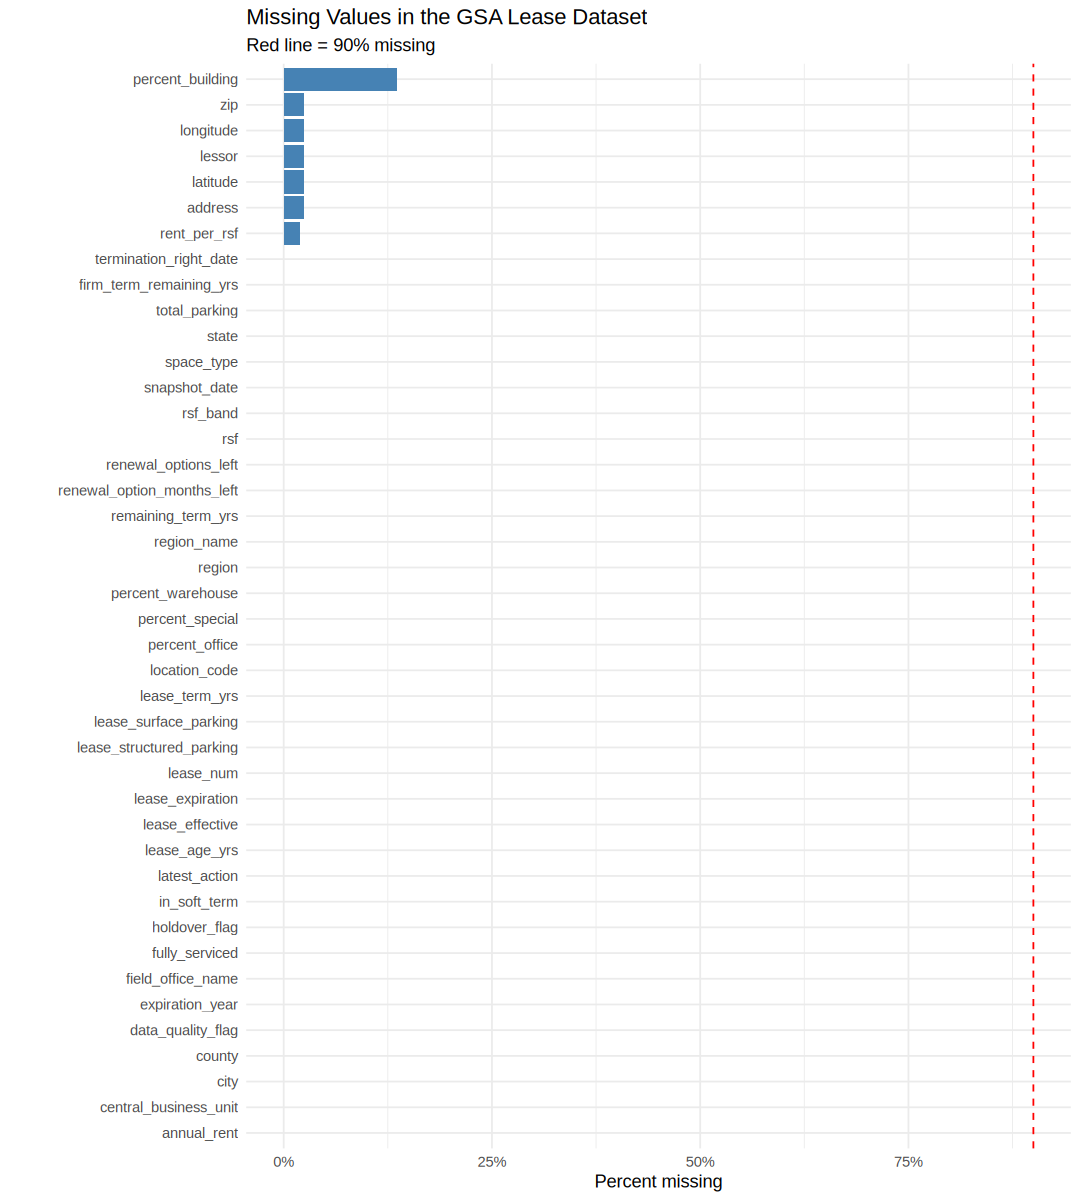

In [38]:

# Plot the percentage of missing values for each column.
# Changed the chart title to match the GSA lease dataset.

options(repr.plot.width = 9, repr.plot.height = 10)

ggplot(missing_table, aes(x = pct_missing, y = fct_reorder(column, pct_missing))) +
  geom_col(fill = "steelblue") +
  geom_vline(xintercept = 0.9, linetype = "dashed", colour = "red") +
  scale_x_continuous(labels = scales::percent) +
  labs(
    title    = "Missing Values in the GSA Lease Dataset",
    subtitle = "Red line = 90% missing",
    x        = "Percent missing",
    y        = NULL
  ) +
  theme_minimal()



### Observation

The chart shows that `percent_building` has the highest percentage of missing values, at approximately 14%.

A few other columns, including `zip`, `longitude`, `latitude`, `address`, and `rent_per_rsf`, also have missing values, but their percentages are relatively low.

The `annual_rent`, `state`, and `lease_expiration` columns have no missing values. These columns are important for analyzing rent by state and identifying upcoming lease expirations.

None of the columns appear to have more than 90% missing values. I will check this using the next code.



### Columns With More Than 90% Missing Values

I will check how many columns have more than 90% missing values. This will help me see whether any columns have too much missing information.


In [39]:

# Count how many columns have more than 90% missing values.
sum(missing_pct > 0.9)


[1] 0


### QUESTION 3 - Understanding Missing Values

**(a) Which columns have the most missing values, and are any more than 90% empty?**

The `percent_building` column has the highest percentage of missing values, at approximately 14%. Other columns, such as `zip`, `longitude`, `latitude`, `address`, and `rent_per_rsf`, also contain some missing values.

However, none of the 42 columns have more than 90% missing values. The result of the previous check was 0.

**(b) Should columns with missing values always be removed?**

No. A column can still contain useful information even when some values are missing.

For example, `latitude` and `longitude` are useful for mapping lease locations. Removing these columns would mean losing geographic information for leases that have valid coordinates.

I will keep these columns for now and consider the missing values when preparing the data for analysis.


# 4. Checking Lease Dates

The GSA dataset includes dates such as lease effective dates and expiration dates.

I will check how R reads these dates before using them in the analysis. This is important because I need to identify which leases are approaching expiration in the next two years.


In [40]:

# Check the data type of the lease expiration column.
# Changed 'order_date' to 'lease_expiration' for the GSA dataset.
class(leases_clean$lease_expiration)


[1] "Date"

### Check the Date Format

The `lease_expiration` column was already stored as a Date. I verify that before using it for expiration analysis, so no extra conversion is needed.


In [41]:

# Confirm that lease_expiration is still stored as a Date.
class(leases_clean$lease_expiration)


[1] "Date"


### Earliest Lease Expiration Date

I will check the earliest lease expiration date in the dataset.

This will help me understand the date range and check whether the dataset includes leases that have already passed their expiration dates.


In [42]:

# Changed the date column to lease_expiration to check the GSA lease dates.
# used na.rm = TRUE to ignore any missing dates when finding the earliest date.
min(leases_clean$lease_expiration, na.rm = TRUE)



[1] "2026-01-31"


### Observation

The earliest lease expiration date is January 31, 2026.

Since the dataset is from August 2026, this shows that some lease records have expiration dates before the dataset's reporting period. These records are worth checking because some leases may still be active under holdover arrangements.

I will keep these records for now rather than remove them without checking their status.



### Latest Lease Expiration Date

I will check the latest lease expiration date using `max()`. This will help me understand the full date range covered by the GSA lease dataset.


In [43]:

# Changed d to leases_clean and order_date to lease_expiration for the GSA dataset.
# Added na.rm = TRUE so missing dates do not affect the result.
max(leases_clean$lease_expiration, na.rm = TRUE)


[1] "2046-08-03"


### Observation

The latest lease expiration date in the GSA dataset is August 3, 2046, while the earliest date was January 31, 2026.

This shows that the dataset includes leases with a wide range of expiration dates. Some have already reached their expiration dates, while others extend many years into the future.

For the renewal analysis in Part 2, I will focus on leases expiring within the next two years rather than including all future expirations.



### Number of Distinct Lease Expiration Dates

I will check how many different lease expiration dates are recorded in the GSA dataset.

The `n_distinct()` function counts the number of unique dates. This helps me understand whether multiple leases share the same expiration date.


In [44]:

# Changed d to leases_clean and order_date to lease_expiration.
# Count the number of different lease expiration dates in the dataset.
n_distinct(leases_clean$lease_expiration)


[1] 2971


### Observation

The GSA lease dataset contains 2,971 distinct lease expiration dates across 7,368 records.

Since there are fewer unique dates than lease records, some leases share the same expiration date. This is important for the renewal analysis because multiple leases may be approaching expiration around the same time.

In Part 2, I will use these dates along with annual rent to identify where the largest amounts of rent are approaching expiration within the next two years.



### QUESTION 4 - Understanding the Lease Expiration Date Range

**What date range does the GSA lease dataset cover, and what does this mean for analyzing upcoming lease expirations?**

The earliest lease expiration date is January 31, 2026, and the latest is August 3, 2046. There are 2,971 distinct expiration dates across 7,368 lease records.

This shows that the dataset includes leases expiring over many years, rather than within a short period.

For the second project objective, I will need to focus on leases approaching expiration within the next two years. I will also need to distinguish upcoming expirations from leases whose expiration dates have already passed.

The expiration dates can help identify when lease obligations may require attention, but they do not tell us whether a lease will actually be renewed.



### Count Leases by Expiration Date

I will count how many lease records have the same expiration date.

This will help me see whether certain dates have more leases expiring than others. It will also help me understand the expiration pattern before analyzing upcoming leases in Part 2.


In [45]:

# Changed d to leases_clean and order_date to lease_expiration.
# Renamed daily to expiration_counts and order_lines to lease_count
# because we are counting lease records instead of customer orders.

expiration_counts <- count(leases_clean, lease_expiration, name = "lease_count")

head(expiration_counts)


lease_expiration,lease_count
<date>,<int>
2026-01-31,1
2026-05-12,1
2026-06-04,1
2026-06-30,6
2026-07-10,1
2026-07-31,17



### Observation

The first six rows show that multiple leases can share the same expiration date. For example, 17 leases have an expiration date of July 31, 2026.

This table only shows the number of leases by date. It does not show how much annual rent is associated with those leases.



### Lease Expirations Over Time

I will plot the number of leases by expiration date to see how expiration dates are distributed across the dataset.


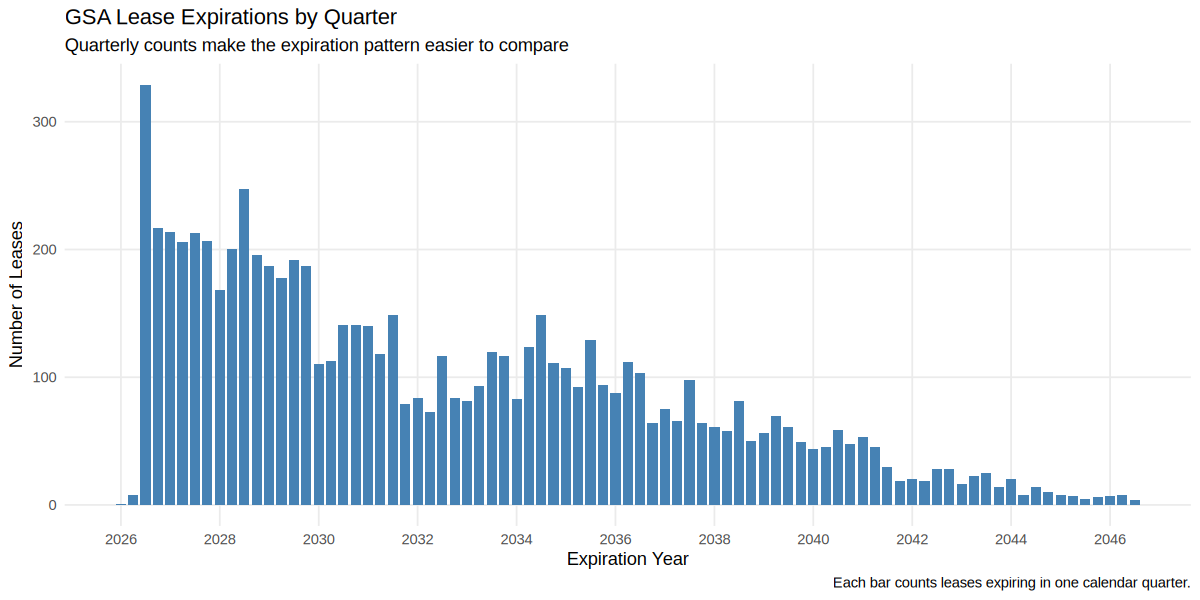

In [46]:
# I group expirations by quarter so the chart is easier to read.
# A daily chart has too many separate dates to compare clearly.

expiration_quarters <- leases_clean %>%
  mutate(
    expiration_quarter = as.Date(cut(lease_expiration, breaks = "quarter"))
  ) %>%
  count(expiration_quarter, name = "lease_count")

options(repr.plot.width = 10, repr.plot.height = 5)

ggplot(expiration_quarters,
       aes(x = expiration_quarter, y = lease_count)) +
  geom_col(fill = "steelblue", width = 75) +
  scale_x_date(date_breaks = "2 years", date_labels = "%Y") +
  labs(
    title = "GSA Lease Expirations by Quarter",
    subtitle = "Quarterly counts make the expiration pattern easier to compare",
    x = "Expiration Year",
    y = "Number of Leases",
    caption = "Each bar counts leases expiring in one calendar quarter."
  ) +
  theme_minimal() +
  theme(panel.grid.minor = element_blank())


### Observation

I grouped the expiration dates by quarter because showing thousands of individual dates made the original chart hard to read. The quarterly bars show where lease expirations are concentrated over time and make busy periods easier to identify.

This is a count of leases, not the amount of rent expiring. In Part 2, I use the exact lease dates and annual rent to measure the next two years of expiration exposure. I also review leases already due as of August 31, 2026, separately.



### Dates With the Most Lease Expirations

I will find the ten dates with the highest number of lease expirations.

This will help me identify dates when several leases are scheduled to expire together.




In [47]:

# Changed daily to expiration_counts because we are working with lease expiration dates.
# Changed order_lines to lease_count to find the dates with the most expiring lease records.

expiration_counts |>
  arrange(desc(lease_count)) |>
  head(10)


lease_expiration,lease_count
<date>,<int>
2026-08-31,198
2026-09-30,65
2028-09-30,52
2028-12-31,46
2028-07-31,44
2027-09-30,42
2026-12-31,39
2026-10-31,37
2027-10-31,36



### Observation

August 31, 2026, has the highest number of lease expirations, with 198 lease records. The next highest date is September 30, 2026, with 65 records.

I also noticed that all ten dates in the table fall at the end of a month. This suggests that month-end dates are common for lease expirations in the GSA dataset.

Some of these dates are close to the dataset's reporting period, so they may need additional attention when analyzing lease expiration and holdover status.

However, the number of expiring leases does not tell us how much rent is involved. I will examine annual rent along with expiration dates in Part 2.


### QUESTION 5 — Understanding Lease Expiration Patterns

**(a) What patterns do you notice in the lease expiration dates?**

The lease expirations are not evenly distributed across dates. August 31, 2026, has the highest number, with 198 lease records, followed by September 30, 2026, with 65 records.

I also noticed that all ten dates with the highest lease counts fall at the end of a month.

**(b) What might explain the higher number of expirations on these dates?**

The pattern suggests that many leases may have expiration dates set at the end of a calendar month. This could explain why certain dates have much higher counts than others.

However, the dataset alone does not confirm why these dates were selected.

**(c) How could these large expiration counts affect the average number of leases expiring per day?**

Dates with unusually high expiration counts could increase the average number of leases expiring per date.

Because some dates have many more expirations than others, the average may not represent a typical expiration date very well. Looking at the distribution and identifying unusually high counts can help avoid misleading conclusions.



# 5. What Does One Row Represent?

Before analyzing the GSA lease data, I need to understand what each row represents.

I will compare the total number of records with the number of unique lease numbers to check whether a lease appears more than once.

This is important because counting the same lease multiple times could affect the annual rent calculations in Part 2.


In [48]:

# Changed d to leases_clean to count the records in the GSA dataset.
nrow(leases_clean)


[1] 7368


### Count Unique Lease Numbers

The dataset contains 7,368 records. I will now count the number of unique lease numbers using `n_distinct()`.

By comparing the number of records with the number of unique lease numbers, I can check whether the same lease appears more than once.


In [49]:

# Changed the original identifier to lease_num to check unique GSA leases.
# Changed d to leases_clean to use our working dataset.
n_distinct(leases_clean$lease_num)


[1] 7368


### Observation - What Does One Row Represent?

The dataset contains 7,368 rows and 7,368 unique lease numbers.

Since the number of rows matches the number of unique lease numbers, each row represents one lease record in this dataset. No lease numbers are repeated.

This is important for the analysis because I can calculate total annual rent without double-counting records due to repeated lease numbers.

I will still check for other data quality issues before using the dataset for analysis.



### Checking the Number of Rows per Lease

The previous results showed that the dataset has 7,368 rows and 7,368 unique lease numbers.

I will group the records by lease number to confirm how many rows are associated with each lease.


In [50]:

# Changed d to leases_clean and order to lease_num for the GSA dataset.
# Renamed lines_per_order to rows_per_lease to match the lease records.
# The grouping and counting methods are the same as the original example.

rows_per_lease <- leases_clean |>
  group_by(lease_num) |>
  summarise(lines = n(), .groups = "drop")

count(rows_per_lease, lines, name = "n_leases")


lines,n_leases
<int>,<int>
1,7368



### Observation

All 7,368 leases have exactly one row in the dataset. This confirms that each row represents a unique lease record.

Unlike the example dataset, where one order could have multiple rows, the GSA dataset has one record per lease number.



### Examining a Lease Record

Since each lease number appears only once, I will look at an individual lease to understand the information stored in each row.

I will use `filter()` to select one lease and `select()` to display the fields most relevant to our project.


In [51]:

# Changed d to leases_clean and order to lease_num.
# Changed the selected columns to show rent, expiration date, and location.
# Used the first lease number because the GSA dataset has no multi-line leases.

leases_clean |>
  filter(lease_num == first(leases_clean$lease_num)) |>
  select(lease_num, annual_rent, lease_expiration, state, holdover_flag)


lease_num,annual_rent,lease_expiration,state,holdover_flag
<chr>,<dbl>,<date>,<chr>,<chr>
LCT00579,3453.84,2027-09-30,CT,N



### Observation

The selected record represents lease LCT00579 in Connecticut. It has an annual rent of $3,453.84 and an expiration date of September 30, 2027.

The `holdover_flag` value is "N", indicating that this lease is not flagged as a holdover.

This example shows how rent, expiration dates, and state information are stored together for each lease. These fields will be useful when analyzing rent expenditures and upcoming lease expirations in Part 2.



### Understanding Annual Rent

In the example dataset, the professor checked whether `paid_price` represented the total price of an order or the price of an individual item.

For the GSA dataset, each lease number appears only once, so the same issue of repeated order prices does not apply.

The `annual_rent` column records the annual rent for each lease. Before adding these values to calculate total rent, I will check whether the rent amounts are recorded consistently and whether there are any unusual values.


### QUESTION 6 - Understanding Annual Rent and Lease Records

**Does each record represent one lease, and can annual rent be added without counting leases twice?**

Yes. I found 7,368 unique lease numbers in 7,368 records. Therefore, each lease appears only once, and adding `annual_rent` across the rows gives the recorded annual rent for the portfolio without duplication from repeated lease rows.

I will still check missing and unusual rent values before using the totals in Part 2.



### Why This Matters

Before calculating total annual rent, I need to understand what each row and rent value represents.

The earlier checks showed that the GSA dataset has 7,368 records and 7,368 unique lease numbers. This means each lease appears once in the dataset.

If a lease appeared multiple times, adding the annual rent from every row could overstate the total. Checking the lease numbers first helps avoid this problem.

I also need to check the rent values themselves because having a value recorded does not necessarily mean it is correct.

These checks will help me calculate total annual rent more accurately in Part 2.



### Building the Tables We Will Use

Now that I have confirmed that each row represents one lease, I will calculate the total annual rent recorded in the GSA dataset.

This will give me an initial rent total before completing the remaining data checks. I will use it later to check whether the cleaning process affected the total rent.


In [52]:

# Changed total_revenue to total_annual_rent and paid_price to annual_rent.
# Changed d to leases_clean because we are using the GSA lease dataset.

total_annual_rent <- sum(leases_clean$annual_rent, na.rm = TRUE)

total_annual_rent


[1] 5838396051



### Observation

The total annual rent recorded in the GSA lease dataset is **\$5,838,396,051.27 (approximately \$5.84 billion)**.

This amount is calculated by adding the annual rent values from all 7,368 lease records.

Since this is the total for the entire dataset, it does not tell us which states have the highest rent. I will use this total as a reference when checking the data and analyzing rent by state in Part 2.

I will also need to check for unusual or invalid rent values before treating this as the final validated total.



### Lease-Level Summary Table

In the original example, the professor creates a summary table with one row per order.

For the GSA dataset, I will create a similar table with one row per lease number. I will include the lease expiration date, state, annual rent, and number of records per lease.

This will help me check the lease-level information before using it in Part 2.


In [53]:

# Changed orders to lease_summary and order to lease_num.
# Replaced the earlier example fields with GSA lease information.
# Kept group_by(), summarise(), first(), n(), and sum() from the original code.

lease_summary <- leases_clean |>
  group_by(lease_num) |>
  summarise(
    lease_expiration = first(lease_expiration),
    state            = first(state),
    lines            = n(),
    annual_rent      = sum(annual_rent, na.rm = TRUE),
    .groups          = "drop"
  )



### Check the Lease Summary Table

I will use `glimpse()` to check the structure of the lease summary table and make sure the columns have the expected data types.


In [54]:

# Changed orders to lease_summary to check the GSA lease summary table.
# Kept the original glimpse() function.

glimpse(lease_summary)


Rows: 7,368
Columns: 5
$ lease_num        <chr> "LAK00070", "LAK00071", "LAK00073", "LAK00100", "LAK0…
$ lease_expiration <date> 2027-11-30, 2037-11-30, 2037-02-28, 2027-11-30, 2033…
$ state            <chr> "AK", "AK", "AK", "AK", "AK", "AK", "AK", "AK", "AK",…
$ lines            <int> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ annual_rent      <dbl> 28238.40, 30772.67, 481855.90, 23860.60, 17830.80, 28…



### Sanity Check - Total Annual Rent

I will check whether the total annual rent in `lease_summary` matches the total calculated earlier from `leases_clean`.

Since both datasets contain 7,368 lease records, the totals should be the same. This check will help confirm that no rent amounts were lost or counted twice when creating the summary table.


In [55]:

# Changed orders to lease_summary and order_value to annual_rent.
# Check whether the lease summary has the same total annual rent.

sum(lease_summary$annual_rent, na.rm = TRUE)


[1] 5838396051


### Observation

The total annual rent in `lease_summary` is \$5,838,396,051.27, which matches the total calculated earlier from `leases_clean`.

The difference is \$0.00, so the lease-level summary preserved the total annual rent.

However, this does not confirm that every rent value is valid. I still need to check for unusual or incorrect values.


### Which Dataset Will I Use?

I use `leases_clean` for all the GSA data-quality checks and then export it for Part 2. Each row represents one lease, so I do not need a separate transaction-level table.


# 6. Exploring the GSA Lease Dataset

I look at rent amounts, lease terms, and expiration patterns to understand the portfolio and check whether the important fields are suitable for analysis.



## Lens A - Annual Rent Distribution

I will use a histogram to examine how annual rent varies across the GSA leases.

This will help me see whether most leases have similar rent amounts or whether some leases have much higher rent than others.


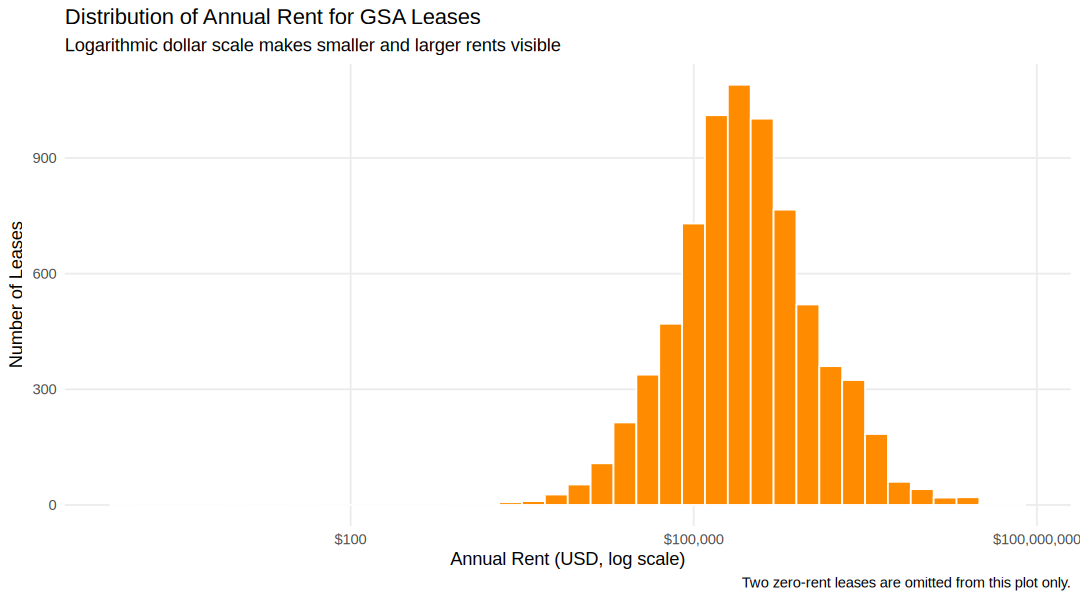

In [56]:
# Annual rents include some very large leases, so I use a log scale.
# I keep zero-rent leases in the data and exclude them only from
# this chart because log10 cannot display zero.

options(repr.plot.width = 9, repr.plot.height = 5)

ggplot(
  filter(lease_summary, !is.na(annual_rent), annual_rent > 0),
  aes(x = annual_rent)
) +
  geom_histogram(bins = 40, fill = "darkorange", color = "white") +
  scale_x_log10(labels = scales::label_dollar()) +
  labs(
    title = "Distribution of Annual Rent for GSA Leases",
    subtitle = "Logarithmic dollar scale makes smaller and larger rents visible",
    x = "Annual Rent (USD, log scale)",
    y = "Number of Leases",
    caption = "Two zero-rent leases are omitted from this plot only."
  ) +
  theme_minimal() +
  theme(panel.grid.minor = element_blank())


### Observation

The annual rent values are right-skewed, meaning most GSA leases have relatively lower annual rents, while a smaller number have much higher rents. I used a logarithmic scale to make the distribution easier to understand because the differences between smaller and larger rent values were difficult to see on the original scale.

I also found two leases with zero annual rent. I kept these records in the cleaned dataset but excluded them from this histogram because zero cannot be displayed on a logarithmic scale. This is important for Objective 1 because a small number of high-value leases can significantly influence the total annual rent reported for each state.


### Summary Statistics for Annual Rent

The histogram showed that annual rent is right-skewed. I will calculate the mean, median, standard deviation, minimum, and maximum annual rent to understand the distribution better.

These statistics will also help me identify whether some lease records have unusually high or low rent values.


In [57]:

# Changed orders to lease_summary and order_value to annual_rent.
# Kept the original summarise() calculations to examine annual rent.

lease_summary |>
  summarise(
    n      = n(),
    mean   = mean(annual_rent, na.rm = TRUE),
    median = median(annual_rent, na.rm = TRUE),
    sd     = sd(annual_rent, na.rm = TRUE),
    min    = min(annual_rent, na.rm = TRUE),
    max    = max(annual_rent, na.rm = TRUE)
  )


n,mean,median,sd,min,max
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
7368,792399,268403.2,2243569,0,62712720



### Observation

The dataset contains 7,368 leases, with an average annual rent of \$792,399 and a median of \$268,403.20.

The mean is much higher than the median, which supports what I noticed in the histogram. Most leases have lower annual rent amounts, while a smaller number of expensive leases increase the average.

The highest recorded annual rent is \$62,712,720, and the lowest is \$0. The standard deviation is also relatively high at approximately \$2.24 million.

I will need to check the zero-rent records and unusually high rent amounts before completing the data cleanup. These values could affect the rent totals used to answer Objective 1.



### QUESTION 7 - Understanding Annual Rent Distribution

**(a) What does the annual rent distribution tell us about the GSA leases?**

The annual rent distribution is right-skewed. Most leases have lower annual rent amounts, while a smaller number have much higher rents.

The average annual rent is approximately \$792,399, while the median is \$268,403.20. The higher mean suggests that expensive leases are pulling the average upward.

**(b) Are there any unusual values that need attention?**

Yes. The minimum recorded annual rent is \$0, while the maximum is \$62,712,720.

These values are worth checking because they could affect the total annual rent calculation. However, I should not assume that they are errors without examining the records.

**(c) Why does this matter for the JLL project?**

The differences in annual rent show why it is important to examine total rent rather than just count leases.

A state with fewer leases could still have a higher total annual rent if those leases are expensive.

In Part 2, I will calculate annual rent by state to answer the first project objective.


## Lens B - Lease Term and Expiration Risk

I summarize remaining lease terms and review holdover status by region. These checks help me understand the expiration fields that I will use in Part 2.


In [58]:

# Changed d to leases_clean and ship_lag_days to remaining_term_yrs.
# Shipping delays do not apply to leases, so I am checking the remaining lease terms.
# Kept the original summarise(), mean(), median(), quantile(), and max() calculations.

leases_clean |>
  filter(!is.na(remaining_term_yrs)) |>
  summarise(
    n      = n(),
    mean   = round(mean(remaining_term_yrs), 2),
    median = median(remaining_term_yrs),
    p90_remaining_term_yrs = quantile(remaining_term_yrs, 0.90),
    max    = max(remaining_term_yrs)
  )


n,mean,median,p90_remaining_term_yrs,max
<int>,<dbl>,<dbl>,<dbl>,<dbl>
7368,5.89,4.79,12.8,19.92



### Observation

The average remaining lease term is 5.89 years, while the median is 4.79 years.

The mean is higher than the median, suggesting that some longer lease terms are increasing the average. The 90th percentile is 12.8 years, and the maximum remaining term is 19.92 years.

These results show that leases have different amounts of time remaining. For Objective 2, I will need to identify which leases are approaching expiration within the next two years and calculate the annual rent associated with them.



### Distribution of Remaining Lease Terms

I will use a histogram to see how the remaining lease terms are distributed across the GSA dataset.

This will help me understand whether most leases have shorter or longer remaining terms and how the values differ across leases.


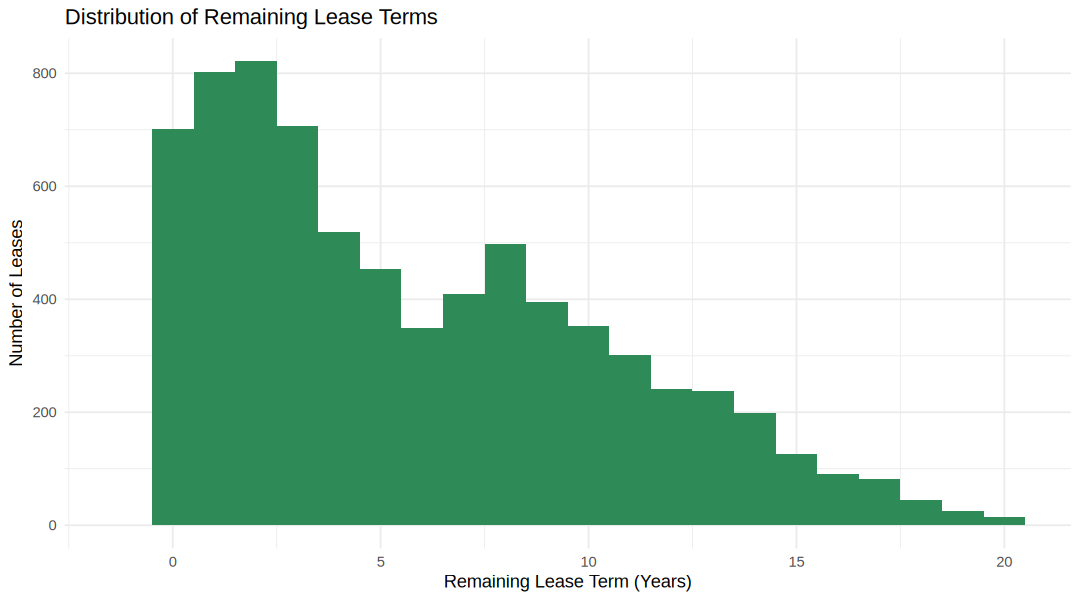

In [59]:

# Changed d to leases_clean and ship_lag_days to remaining_term_yrs.
# The histogram now shows remaining lease terms instead of shipping delays.
# Kept the original binwidth, color, and plotting functions.

ggplot(filter(leases_clean, !is.na(remaining_term_yrs)), aes(x = remaining_term_yrs)) +
  geom_histogram(binwidth = 1, fill = "seagreen") +
  labs(title = "Distribution of Remaining Lease Terms",
       x = "Remaining Lease Term (Years)",
       y = "Number of Leases") +
  theme_minimal()



### Observation

The histogram shows that many GSA leases have shorter remaining terms, especially between 0 and 4 years.

The number of leases generally decreases as the remaining term increases, although there are also several leases with longer terms extending toward 20 years.

This pattern is consistent with the earlier summary statistics, where the average remaining term was 5.89 years and the median was 4.79 years.

For Objective 2, I will need to examine leases approaching expiration within the next two years and calculate how much annual rent is associated with them.



### Holdover Status by Region

I will check the number and percentage of leases marked as holdovers in each GSA region.

The `holdover_flag` column identifies whether a lease is marked as a holdover, while `region` shows its geographic region.

This will help me compare holdover status across regions before analyzing upcoming lease expirations.


In [60]:

# Changed d to leases_clean to use the GSA dataset.
# Changed platform to region and status_2 to holdover_flag.
# Kept the original counting and percentage calculations.

leases_clean |>
  count(region, holdover_flag) |>
  group_by(region) |>
  mutate(pct = round(100 * n / sum(n), 1)) |>
  arrange(region, desc(n))


region,holdover_flag,n,pct
<dbl>,<chr>,<int>,<dbl>
1,N,326,100.0
2,N,486,99.8
2,Y,1,0.2
3,N,715,99.4
3,Y,4,0.6
4,N,1340,99.3
4,Y,10,0.7
5,N,856,99.7
5,Y,3,0.3



### Observation

The table shows that most leases in all 11 GSA regions are not marked as holdovers.

Region 4 has the highest number of holdover leases, with 10, while Region 11 has the highest percentage, at 1.0%.

Overall, 35 out of 7,368 leases are marked as holdovers, which is approximately 0.48% of the dataset.

Although the number of holdover leases is small, these records may need additional attention when reviewing lease expiration dates.

This is relevant to Objective 2 because holdover status can help us understand leases that may require renewal or other leasing decisions.



### Checking Holdover Lease Records

In the original example, this code counts the reasons recorded for order problems.

For the GSA dataset, I will use `holdover_flag` to count the recorded holdover statuses.

This will help me check how many leases are marked as holdovers and whether any records are missing this information.


In [61]:

# Changed d to leases_clean and reason to holdover_flag.
# The original code counts non-missing reasons for order problems.
# Here, I am counting the recorded holdover statuses instead.

leases_clean |>
  filter(!is.na(holdover_flag)) |>
  count(holdover_flag, sort = TRUE)


holdover_flag,n
<chr>,<int>
N,7333
Y,35



### Observation

Out of 7,368 leases, 7,333 are marked "N" and 35 are marked "Y" for holdover status.

This means approximately 99.52% of leases are not flagged as holdovers, while 0.48% are flagged as holdovers.

The counts add up to the total number of records, so there are no missing holdover statuses.

Although only a small number of leases are marked as holdovers, they are worth considering when reviewing lease expirations in Part 2.



### Checking Lease Expiration Dates by Region

I will check whether lease expiration dates are recorded for all GSA regions.

The `is.na()` function checks for missing dates. By grouping the results by region, I can see whether any regions have missing expiration information.

This is important because missing expiration dates could affect the renewal analysis in Part 2.


In [62]:

# Changed d to leases_clean and platform to region.
# Changed delivered_date to lease_expiration because this dataset contains lease dates.
# Renamed has_delivery_date to has_expiration_date to match the GSA dataset.

leases_clean |>
  count(region, has_expiration_date = !is.na(lease_expiration))


region,has_expiration_date,n
<dbl>,<lgl>,<int>
1,TRUE,326
2,TRUE,487
3,TRUE,719
4,TRUE,1350
5,TRUE,859
6,TRUE,349
7,TRUE,990
8,TRUE,504
9,TRUE,946



### Observation

All 11 GSA regions have lease expiration dates recorded for every lease. The `has_expiration_date` column shows TRUE for all 7,368 records.

Region 4 has the highest number of lease records, with 1,350, while Region 1 has the lowest, with 326.

There are no missing lease expiration dates in any region. This is important for Objective 2 because I will use these dates to identify leases approaching expiration within the next two years.

However, I still need to consider lease status and date validity before interpreting the results as renewal exposure.



### QUESTION 8 - Lease Status and Expiration Data

**(a) Which GSA regions have the highest number and percentage of holdover leases? Why is it important to consider both?**

Region 4 has the highest number of holdover leases, with 10 records. However, Region 11 has the highest holdover percentage, at 1.0%.

This shows why I should consider both counts and percentages. A region with more leases may naturally have more holdovers, even if its holdover percentage is relatively low.

**(b) Are there any missing values in the `holdover_flag` column? What does this tell us?**

The dataset contains 7,333 leases marked "N" and 35 marked "Y". Together, these account for all 7,368 records.

This shows that there are no missing holdover statuses. However, it does not confirm whether every recorded status is correct.

**(c) Are lease expiration dates available for every region? Why is this important for the analysis?**

Yes. All 11 GSA regions have expiration dates recorded for every lease. There are no missing values in the `lease_expiration` column.

This is important because I will use these dates to identify leases approaching expiration within the next two years.

However, having complete expiration dates does not necessarily mean every lease will be renewed. I will need to consider the lease status and annual rent when interpreting renewal exposure in Part 2.


## Lens C - Lease Portfolio Structure

I examine the number of lease records and regional distribution. Each row represents one lease, so I focus on lease characteristics instead of transaction or product information.


In [63]:

# Changed orders to lease_summary because we are working with lease records.
# Changed n_orders to n_leases to match the GSA dataset.
# Kept the original count() and percentage calculation.

lease_summary |>
  count(lines, name = "n_leases") |>
  mutate(pct = round(100 * n_leases / sum(n_leases), 1))


lines,n_leases,pct
<int>,<int>,<dbl>
1,7368,100



### Observation

All 7,368 leases have exactly one row in the dataset, representing 100% of the lease records.

This confirms the earlier finding that each row represents one unique lease number. It also supports using the lease records to calculate total annual rent without double-counting repeated lease numbers.



### Distribution of Leases by GSA Region

I will check how the lease records are distributed across the 11 GSA regions.

The `count()` function shows how many leases are in each region, while `mutate()` calculates the percentage of total leases.

This will help me understand the geographic distribution of the dataset before analyzing rent by state in Part 2.


In [64]:

# Changed orders to leases_clean and platform to region.
# This counts leases by GSA region instead of orders by sales platform.
# Kept the original count() and percentage calculation.

leases_clean |>
  count(region) |>
  mutate(pct = round(100 * n / sum(n), 1))


region,n,pct
<dbl>,<int>,<dbl>
1,326,4.4
2,487,6.6
3,719,9.8
4,1350,18.3
5,859,11.7
6,349,4.7
7,990,13.4
8,504,6.8
9,946,12.8



### Observation

Region 4 has the highest number of leases, with 1,350 records (18.3%), followed by Region 7 with 990 leases (13.4%) and Region 9 with 946 leases (12.8%).

Region 1 has the fewest leases, with 326 records (4.4%).

This shows that lease records are not evenly distributed across the 11 GSA regions.

However, having more leases does not necessarily mean a region has higher total annual rent. In Part 2, I will use annual rent and state information to identify where the federal government pays the most rent.



### QUESTION 10 - Lens D: Lease Portfolio Structure

**(a) What does the dataset tell us about the number of records per lease? What are the limitations of this finding?**

The dataset contains 7,368 records and 7,368 unique lease numbers. All leases have exactly one row, representing 100% of the records.

This confirms that each lease number appears only once in the current dataset. However, it does not tell us whether the same lease existed in earlier datasets or whether its terms changed over time.

To study lease history, I would need records from previous reporting periods.

**(b) Which GSA regions have the most leases, and what can we conclude from these differences?**

Region 4 has the highest number of leases, with 1,350 records (18.3%), followed by Region 7 with 990 (13.4%) and Region 9 with 946 (12.8%).

Region 1 has the fewest leases, with 326 records (4.4%).

These results show that the number of leases varies across regions. However, lease counts alone cannot tell us which regions have the highest annual rent or the greatest renewal exposure.

For the final analysis, I will need to compare annual rent and upcoming lease expirations by state before making leasing recommendations.


# 7. Free Exploration

I use additional GSA-specific checks to explore lease expiration patterns and data-quality issues related to rent, dates, and locations.


### Lease Expirations by Day of the Week

I check whether lease expirations cluster on certain weekdays. The `wday()` function identifies weekdays, and I compare the lease counts and associated annual rent. This is an exploratory check, not a replacement for the exact-date analysis in Part 2.


In [65]:

# Changed orders to lease_summary and order_date to lease_expiration.
# Changed n_orders to n_leases and revenue to annual_rent.
# Kept the original weekday grouping and summary calculations.

lease_summary |>
  mutate(weekday = wday(lease_expiration, label = TRUE)) |>
  group_by(weekday) |>
  summarise(
    n_leases    = n(),
    annual_rent = round(sum(annual_rent, na.rm = TRUE), 2)
  )


weekday,n_leases,annual_rent
<ord>,<int>,<dbl>
Sun,1092,934915284
Mon,1308,997199945
Tue,899,698973242
Wed,885,652724045
Thu,956,814531940
Fri,1081,915001105
Sat,1147,825050490



### Observation

Monday has the highest number of lease expirations, with 1,308 leases and approximately \$997.20 million in associated annual rent.

Wednesday has the lowest number, with 885 leases and approximately \$652.72 million in annual rent.

I also noticed that lease expiration dates fall on all seven days of the week, including weekends. This suggests that expiration dates are based on calendar dates rather than only business days.

This analysis shows how expiration dates are distributed across weekdays, but it does not tell us which states have the highest upcoming renewal exposure. I will examine that in Part 2.



### Three Additional Data Checks

I will use these three exploration cells to check data-quality issues that could affect the JLL analysis.

I will examine zero or negative annual rent values, lease expiration information, and missing geographic data.

These checks will help me decide whether any additional cleaning is needed before exporting the dataset for Part 2.


In [66]:

# Exploration 1
# Added this check to find leases with zero or negative annual rent.
# These values could affect the rent calculations in Part 2.

leases_clean |>
  summarise(
    zero_rent = sum(annual_rent == 0, na.rm = TRUE),
    negative_rent = sum(annual_rent < 0, na.rm = TRUE)
  )


zero_rent,negative_rent
<int>,<int>
2,0


### Observation — inspected zero-rent leases

The two zero-annual-rent records are leases **LNY23416** (Champlain, New York, at I-87 Canadian Border) and **LMO60046** (St. Louis, Missouri, at 1222 Spruce St). Both have **0 rentable square feet** and government lessors (New York Department of Transportation and City of St. Louis, respectively). They may represent no-cost governmental arrangements, although the dataset alone cannot confirm the contract terms. I therefore retain both rows unchanged; their annual rent contributes $0, not missing rent, to portfolio totals. The next code cell displays the underlying records so this decision is auditable.

In [67]:
# Instructor-requested inspection: preserve both zero-rent lease records.
zero_rent_detail <- leases_clean |>
  filter(!is.na(annual_rent), annual_rent == 0) |>
  select(lease_num, city, state, address, lessor, rsf,
         annual_rent, data_quality_flag)
print(zero_rent_detail, n = Inf, width = Inf)
stopifnot(nrow(zero_rent_detail) == 2,
          all(zero_rent_detail$rsf == 0))

# A tibble: 2 × 8
  lease_num city      state address              lessor                rsf
  <chr>     <chr>     <chr> <chr>                <chr>               <dbl>
1 LNY23416  CHAMPLAIN NY    I-87 CANADIAN BORDER NEW YORK  DOT           0
2 LMO60046  ST. LOUIS MO    1222 SPRUCE ST       CITY OF ST LOUIS MO     0
  annual_rent data_quality_flag
        <dbl> <chr>            
1           0 zero_rsf         
2           0 zero_rsf         



### Exploration 2 - Lease Expiration and Holdover Status

I will check how many leases have expiration dates before August 31, 2026, and compare them with their holdover status.

This will help me identify leases that have already passed their expiration dates and see whether they are marked as holdovers.

I will use August 31, 2026, as the reference date because it is the reporting date of the GSA dataset.


In [68]:
# Separate pre-snapshot holdovers, snapshot-day expirations and later leases.
leases_clean |>
  mutate(expiration_group = case_when(
    lease_expiration < as.Date("2026-08-31") ~ "Before snapshot",
    lease_expiration == as.Date("2026-08-31") ~ "On snapshot date",
    lease_expiration > as.Date("2026-08-31") ~ "After snapshot",
    TRUE ~ "Missing expiration date"
  )) |>
  count(expiration_group, holdover_flag)

expiration_group,holdover_flag,n
<chr>,<chr>,<int>
After snapshot,N,7135
Before snapshot,Y,35
On snapshot date,N,198



### Observation

The results show that all 35 leases with expiration dates before August 31, 2026, are marked as holdovers ("Y").

The remaining 7,333 leases have expiration dates on or after August 31, 2026, and are marked as non-holdovers ("N").

I did not find any differences between the expiration-date groups and their recorded holdover status.

This suggests that the holdover flag is consistent with the expiration dates in the dataset. I will keep these records because the results do not provide a reason to remove them.

This is important for Objective 2 because I need to separate leases that have already expired from those approaching expiration in the next two years.



### Exploration 3 - Missing Geographic Information

I will check for missing values in the state, address, latitude, and longitude columns.

These fields are important for understanding where the leases are located. State information will be used to compare rent across states, while latitude and longitude can help with mapping individual lease locations.

I will check how much geographic information is missing before deciding whether any cleaning is needed.


In [69]:

# Exploration 3
# Added this check to count missing geographic information in the GSA dataset.
# These fields are useful for mapping and comparing lease locations in Part 2.

leases_clean |>
  summarise(
    missing_state = sum(is.na(state)),
    missing_address = sum(is.na(address)),
    missing_latitude = sum(is.na(latitude)),
    missing_longitude = sum(is.na(longitude))
  )


missing_state,missing_address,missing_latitude,missing_longitude
<int>,<int>,<int>,<int>
0,182,182,182



### Observation

All 7,368 leases have state information, so there are no missing values in the `state` column.

However, 182 records (2.47%) are missing addresses, and 182 records are also missing latitude and longitude values.

These missing values could affect mapping individual lease locations. However, the state information is complete, so these records may still be useful for state-level analysis.

I will keep these records for now rather than remove them because of missing geographic details.

This is important for Objective 3, where I will map annual rent and upcoming lease expirations by state.



# 8. Data Cleanup Summary

This section summarizes what I found while examining the GSA lease dataset and identifies the data-quality issues that still need to be addressed before exporting the cleaned file.



### Findings So Far

The original GSA lease dataset contains 7,368 rows and 42 columns. Each row represents one lease, and all lease numbers are unique.

The total recorded annual rent is \$5,838,396,051.27. There are no missing annual rent values, but 2 leases have zero annual rent.

The lease expiration dates range from January 31, 2026, to August 3, 2046. All leases have recorded expiration dates, and the 35 leases expiring before the dataset's reporting date are marked as holdovers.

All leases have state information. However, 182 records are missing addresses, and 182 records are missing latitude and longitude values.

The annual rent distribution is right-skewed, with a small number of leases having much higher rent amounts than others.

### Remaining Data Checks

Before exporting the cleaned dataset, I still need to review unusual rent values, existing data-quality flags, and any other invalid values.

I will also compare the original and cleaned datasets to document what changed and confirm that valid lease records and rent values were preserved.



## Five Questions This Data Raised That I Cannot Yet Answer

1. Which states have the highest annual rent, and is that because they have more leases or because their leases are more expensive?

2. Which states have the largest amount of annual rent associated with leases expiring in the next two years?

3. Are the two leases with zero annual rent legitimate arrangements, or are their rent amounts missing from the original records?

4. Why are 182 leases missing geographic coordinates, and can their locations be verified using other information?

5. How should JLL prioritize states where both total annual rent and upcoming lease expirations are high?



## Three Data Quality Problems I Found

**1. Zero Annual Rent Values**

I found 2 leases with zero annual rent. I am not sure whether these are valid arrangements or reporting issues. If the rent amounts were entered incorrectly, including them could underestimate total rent in the affected states. I kept these records because I do not have enough information to change them.

**2. Missing Geographic Information**

I found 182 records with missing addresses, and 182 records with missing latitude and longitude values. This could make it difficult to map individual lease locations. However, all 7,368 leases have state information, so I can still include them in state-level analysis if their state values are valid.

**3. Leases With Past Expiration Dates**

I found 35 leases with expiration dates before August 31, 2026. All 35 are marked as holdovers. These records are not necessarily errors, but they could create misleading results if I treated every expiration date as an upcoming renewal. I need to distinguish these leases from those expiring in the next two years.



## My Analysis Focus - Geographic Rent and Lease Renewals

For the JLL project, I will focus on geographic rent distribution and upcoming lease renewals. I chose this approach because the main goal is to understand where the federal government pays the most rent and where large amounts of that rent may be coming up for renewal.

During my exploration, I found that the dataset contains 7,368 leases with approximately \$5.84 billion in recorded annual rent. All leases have state and expiration-date information, which makes it possible to analyze rent and renewal exposure by state.

In Part 2, I will identify the states with the highest annual rent, calculate how much rent is associated with leases expiring in the next two years, and create state-level visualizations.

I will use these findings to explain which geographic markets JLL may want to prioritize for leasing and renewal planning.



# 9. Final Data Validation and Cleaning

## Before-and-After Data Quality Check

I will compare the original GSA dataset with my cleaned working dataset to confirm how many rows and columns were preserved.

I will also check whether the annual rent totals changed during cleaning.

This is important because I do not want to accidentally remove valid leases or change rent amounts before using the data for JLL's analysis.


In [70]:

# Added a before-and-after check to validate the cleaning process.
# Compare dataset dimensions and annual rent before and after cleaning.

tibble(
  dataset = c("Original", "Cleaned"),
  rows = c(nrow(leases), nrow(leases_clean)),
  columns = c(ncol(leases), ncol(leases_clean)),
  total_annual_rent = c(
    sum(leases$annual_rent, na.rm = TRUE),
    sum(leases_clean$annual_rent, na.rm = TRUE)
  )
)


dataset,rows,columns,total_annual_rent
<chr>,<int>,<int>,<dbl>
Original,7368,42,5838396051
Cleaned,7368,42,5838396051



### Observation

The original and cleaned datasets both contain 7,368 rows and 42 columns.

The total annual rent is also unchanged at approximately \$5.84 billion.

This confirms that the cleaning process has preserved the number of lease records and the overall rent total. So far, I have standardized the column names and checked several potential data-quality issues without removing records.

I still need to validate the individual values before exporting the dataset for Part 2.


In [71]:

# Added this check to identify existing data-quality or warning fields.
# Review the available column names before deciding what to clean.

names(leases_clean)[
  grepl(
    "flag|quality|warning|issue|error|status",
    names(leases_clean),
    ignore.case = TRUE
  )
]


[1] "holdover_flag"     "data_quality_flag"


### Checking the Existing Data Quality Flag

The GSA dataset already includes a `data_quality_flag` column.

I will check which values appear in this column and how many leases belong to each category.

This will help me identify records that may need additional review before exporting the cleaned dataset.


In [72]:

# Added this check to understand the existing data_quality_flag column.
# Count the number of leases in each category, including missing values.

leases_clean |>
  count(data_quality_flag, sort = TRUE)


data_quality_flag,n
<chr>,<int>
ok,7160
zero_rsf,148
rent_psf_outlier,60



### Observation

The `data_quality_flag` column shows that 7,160 leases are marked as `ok`, while 148 are flagged as `zero_rsf` and 60 as `rent_psf_outlier`.

This means 208 leases (2.82%) have existing data-quality flags.

I should investigate these records before making changes. The flags may affect calculations involving rentable square footage or rent per square foot, but they do not automatically mean the annual rent values are incorrect.

For now, I will keep these records and check the underlying values.


The **60 `rent_psf_outlier` records** are listed in full in the next table. These are separate from the **148 `zero_rsf`** records, and I do not change either category without external verification.

### All 60 rent-per-square-foot outliers — instructor-requested review

The source dataset flags 60 leases as `rent_psf_outlier`. I list all of them rather than delete or cap their annual rents. The source does not establish which, if any, are data entry errors.

In [73]:
rent_psf_outliers <- leases_clean |>
  filter(data_quality_flag == "rent_psf_outlier") |>
  select(lease_num, city, state, address, lessor,
         rsf, annual_rent, rent_per_rsf, data_quality_flag) |>
  arrange(desc(rent_per_rsf))
print(rent_psf_outliers, n = Inf, width = Inf)
stopifnot(nrow(rent_psf_outliers) == 60,
          sum(leases_clean$data_quality_flag == "zero_rsf", na.rm = TRUE) == 148)

# A tibble: 60 × 9
   lease_num city               state address                       
   <chr>     <chr>              <chr> <chr>                         
 1 LTX01502  MCALLEN            TX    6086 N 10TH ST                
 2 LVA00594  FALLS CHURCH       VA    5107 LEESBURG PIKE            
 3 LMD00560  GERMANTOWN         MD    12410 MILESTONE CENTER DR     
 4 LWA06476  ISSAQUAH           WA    6501 173RD SE                 
 5 LOR06739  PORTLAND           OR    4700 SW COUNCIL CREST DR      
 6 LCA00942  LOS GATOS          CA    LOMA PRIETA #3                
 7 LCA03169  OAKLAND            CA    1250 MARTIN LUTHER KING JR WAY
 8 LWA07020  KENNEWICK          WA    JUMP OFF JOE RD               
 9 LMD01886  BRANDYWINE         MD    2313 KNOTWEED CT              
10 LVA00763  DULLES AIRPORT     VA    21000 ATLANTIC BLVD           
11 LGA02400  SAVANNAH           GA    1801 KERRY ST                 
12 LWA06997  TACOMA             WA    5913 6TH ST NE                
13 LTX17485  EL

### State and territory code validation

The state field contains 56 distinct jurisdiction codes. The U.S. state abbreviations, **DC**, and the territorial codes **AS** (American Samoa), **GU** (Guam), **MP** (Northern Mariana Islands), **PR** (Puerto Rico) and **VI** (U.S. Virgin Islands) are valid reporting jurisdictions. They remain in the cleaned data even when a contiguous-U.S. map cannot display them.

In [74]:
# Verify every jurisdiction against the 50 states, DC and five territories.
valid_state_codes <- c(state.abb, "DC", "AS", "GU", "MP", "PR", "VI")
state_code_validation <- leases_clean |>
  count(state, name = "lease_count") |>
  mutate(valid_jurisdiction = state %in% valid_state_codes) |>
  arrange(state)
print(state_code_validation, n = Inf)
stopifnot(n_distinct(leases_clean$state) == 56,
          all(state_code_validation$valid_jurisdiction),
          !anyNA(leases_clean$state))

# A tibble: 56 × 3
   state lease_count valid_jurisdiction
   <chr>       <int> <lgl>             
 1 AK             85 TRUE              
 2 AL            121 TRUE              
 3 AR             72 TRUE              
 4 AS              5 TRUE              
 5 AZ            159 TRUE              
 6 CA            649 TRUE              
 7 CO            173 TRUE              
 8 CT             53 TRUE              
 9 DC            147 TRUE              
10 DE             34 TRUE              
11 FL            409 TRUE              
12 GA            184 TRUE              
13 GU             15 TRUE              
14 HI             60 TRUE              
15 IA             68 TRUE              
16 ID             61 TRUE              
17 IL            196 TRUE              
18 IN             98 TRUE              
19 KS             69 TRUE              
20 KY            103 TRUE              
21 LA            155 TRUE              
22 MA            111 TRUE              
23 MD            199 


## Final Cleaning Decisions

After reviewing the GSA lease dataset, I decided to keep all 7,368 lease records.

I standardized the column names and checked for missing values, duplicate lease numbers, invalid annual rent amounts, and unusual expiration dates.

I also reviewed the existing data quality flags. The dataset contains 148 records flagged as `zero_rsf` and 60 flagged as `rent_psf_outlier`.

I kept these records because the flags alone do not prove that the annual rent amounts are incorrect.

I also kept the 2 zero-rent leases and 182 records with missing geographic information. All leases have state information, so they can still contribute to state-level analysis.

The 35 holdover leases were retained, but I will distinguish them from future lease expirations in Part 2.

I did not replace missing values with estimates or remove records without a clear reason. The cleaned dataset preserves the original lease records and annual rent amounts.


In [75]:

# Final validation before exporting the cleaned GSA dataset.
# Check unique leases and missing values in the key analysis fields.

leases_clean |>
  summarise(
    total_leases = n(),
    unique_leases = n_distinct(lease_num),
    duplicate_leases = n() - n_distinct(lease_num),
    missing_lease_num = sum(is.na(lease_num)),
    missing_state = sum(is.na(state)),
    missing_annual_rent = sum(is.na(annual_rent)),
    missing_expiration = sum(is.na(lease_expiration))
  )


total_leases,unique_leases,duplicate_leases,missing_lease_num,missing_state,missing_annual_rent,missing_expiration
<int>,<int>,<int>,<int>,<int>,<int>,<int>
7368,7368,0,0,0,0,0



### Final Validation Results

The final dataset contains 7,368 leases with no duplicate lease numbers.

There are no missing values in the lease number, state, annual rent, or expiration date columns.

I kept all lease records and preserved the original annual rent total. The data-quality flags and missing individual-location details remain documented.

The dataset is ready to be exported for the JLL analysis in Part 2.


In [76]:

# Export the cleaned dataset for use in Part 2.
# Keep all validated lease records and existing data-quality flags.

write_csv(
  leases_clean,
  "/content/cs1_gsa_leases_cleaned.csv"
)

# Confirm that the cleaned CSV was created.
file.exists("/content/cs1_gsa_leases_cleaned.csv")


[1] TRUE

In [77]:

# Read the exported CSV to confirm it was saved correctly.
# Check the number of rows, columns, and total annual rent.

exported_leases <- read_csv(
  "/content/cs1_gsa_leases_cleaned.csv",
  show_col_types = FALSE
)

tibble(
  check = c("Rows", "Columns", "Total Annual Rent"),
  original = c(
    nrow(leases_clean),
    ncol(leases_clean),
    sum(leases_clean$annual_rent, na.rm = TRUE)
  ),
  exported = c(
    nrow(exported_leases),
    ncol(exported_leases),
    sum(exported_leases$annual_rent, na.rm = TRUE)
  )
)


check,original,exported
<chr>,<dbl>,<dbl>
Rows,7368,7368
Columns,42,42
Total Annual Rent,5838396051,5838396051


In [78]:

# Compare the raw CSV headers with the cleaned column names.
# This shows whether any column names actually changed.

raw_headers <- names(
  read_csv(
    "/content/cs1_gsa_leases_2026_08.csv",
    n_max = 0,
    show_col_types = FALSE
  )
)

column_comparison <- tibble(
  original_name = raw_headers,
  cleaned_name = names(leases_clean)
) |>
  mutate(changed = original_name != cleaned_name)

column_comparison |>
  count(changed)


changed,n
<lgl>,<int>
FALSE,42



### Observation - Column Names

I compared the original CSV headers with the cleaned dataset and found that all 42 column names remained unchanged.

I applied the column-name standardization functions from the original example, but the GSA dataset already had consistent names.

No renaming was necessary, and all 42 columns were preserved.



## Data Types - Before and After Cleaning

I will compare the data types in the original GSA dataset with those in the cleaned dataset.

This will show whether any columns needed type conversion during cleaning and help confirm that important fields such as annual rent and lease expiration dates are stored correctly.


In [79]:

# Compare original and cleaned column types.
# Use the same read_csv() method used to import the GSA data.

raw_for_types <- read_csv(
  "/content/cs1_gsa_leases_2026_08.csv",
  show_col_types = FALSE
)

type_comparison <- tibble(
  column = names(leases_clean),
  original_type = sapply(raw_for_types, function(x) class(x)[1]),
  cleaned_type = sapply(leases_clean, function(x) class(x)[1])
) |>
  mutate(changed = original_type != cleaned_type)

# Count columns with and without type changes.
type_comparison |>
  count(changed)

# Show the types of the main JLL analysis fields.
type_comparison |>
  filter(column %in% c(
    "lease_num", "state", "annual_rent",
    "lease_expiration", "holdover_flag", "data_quality_flag"
  ))


changed,n
<lgl>,<int>
FALSE,42


column,original_type,cleaned_type,changed
<chr>,<chr>,<chr>,<lgl>
lease_num,character,character,FALSE
state,character,character,FALSE
lease_expiration,Date,Date,FALSE
annual_rent,numeric,numeric,FALSE
holdover_flag,character,character,FALSE
data_quality_flag,character,character,FALSE



### Observation - Data Types

I compared the original and cleaned datasets and found that all 42 columns retained their original data types.

The important fields were already stored appropriately. Annual rent is numeric, lease expiration is a Date, and lease numbers, states, and quality flags are character fields.

No additional data type conversion was needed for these fields. I kept the original types because they support the planned analysis.


In [80]:

# Check whether these fields already exist in the original GSA file.
# Compare them with the cleaned dataset before claiming they were created.

fields_to_check <- c(
  "remaining_term_yrs",
  "lease_expiration",
  "annual_rent",
  "lease_num"
)

tibble(
  field = fields_to_check,
  in_original = fields_to_check %in% names(raw_for_types),
  in_cleaned = fields_to_check %in% names(leases_clean)
)


field,in_original,in_cleaned
<chr>,<lgl>,<lgl>
remaining_term_yrs,TRUE,TRUE
lease_expiration,TRUE,TRUE
annual_rent,TRUE,TRUE
lease_num,TRUE,TRUE



### Observation - Derived Fields

I checked the original and cleaned datasets and confirmed that `remaining_term_yrs`, `lease_expiration`, `annual_rent`, and `lease_num` were already present in the source data.

I also created a separate `lease_summary` table during exploration using `group_by()` and `summarise()`. However, each row in the original dataset already represents one lease, so I did not need to replace the original records with this summary.

I did not add any new derived columns to the exported dataset. I kept the existing fields and will calculate additional measures, such as rent associated with leases expiring in the next two years, during Part 2.


### Additional Validation - Existing Derived Fields

The source file already includes `rent_per_rsf` and `expiration_year`, so I did not create or overwrite these columns. As a final quality check, I verify that `rent_per_rsf` agrees with annual rent divided by rentable square feet for rows with positive RSF, allowing one cent per square foot for rounding. I also check that `expiration_year` matches the year in `lease_expiration`. These checks do not change the exported dataset.


In [81]:
# Validate two existing derived columns without changing leases_clean.
rent_psf_check <- leases_clean |>
  filter(!is.na(rsf), rsf > 0, !is.na(annual_rent),
         !is.na(rent_per_rsf)) |>
  summarise(
    checked_leases = n(),
    rent_psf_mismatches = sum(abs(annual_rent / rsf - rent_per_rsf) > 0.01)
  )

expiration_year_check <- leases_clean |>
  summarise(
    checked_leases = sum(!is.na(lease_expiration) & !is.na(expiration_year)),
    expiration_year_mismatches = sum(
      !is.na(lease_expiration) & !is.na(expiration_year) &
        as.integer(format(lease_expiration, "%Y")) != expiration_year,
      na.rm = TRUE
    )
  )

print(rent_psf_check)
print(expiration_year_check)


# A tibble: 1 × 2
  checked_leases rent_psf_mismatches
           <int>               <int>
1           7220                   0
# A tibble: 1 × 2
  checked_leases expiration_year_mismatches
           <int>                      <int>
1           7368                          0



## Final Missing-Value and Invalid-Value Review

I reviewed the missing-value checks, duplicate checks, rent values, expiration dates, and existing data-quality flags.

The dataset has no missing lease numbers, states, annual rent amounts, or expiration dates. I also found no duplicate lease numbers or negative annual rent values.

I kept the 2 zero-rent leases and the 208 records with existing data-quality flags because I could not confirm that their values were incorrect.

I also retained records with missing address or coordinate information because their state information is available for state-level analysis.

No missing values were filled with estimates, and no lease records were deleted. These limitations will be considered when interpreting the results in Part 2.

The exported dataset contains 7,368 leases and 42 columns, with the total annual rent preserved.
